# 03 — Habitat suitability: where can the cane toad live?

Notebook 02 showed that the western front is **slowing down** and that the southern front barely moves. A linear extrapolation can't explain either. Here we ask: **are the fronts approaching places where the climate does not allow toads to live?**

**Task:** model the relationship between toad presence and the environment (climate, elevation, rivers), then map the predicted habitat suitability across Australia.

| Item | Choice |
|---|---|
| Unit | 25 km grid cell over Australia |
| Response | Toad recorded in the cell (1) vs background (0): *presence-background* data |
| Predictors | 6 WorldClim bioclimatic variables, elevation, distance to rivers |
| Models | Logistic regression (GLM), MaxEnt, Random Forest, LightGBM |
| Validation | **Spatial block cross-validation**, AUC |

See `docs/06_modelos.md` (Spanish) for the reasoning behind each choice.

In [1]:
import sys
from pathlib import Path

import elapid
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "src"))
from download import download_australia_outline
from environment import BIOCLIM_VARIABLES, environmental_grid
from front import AUSTRALIAN_ALBERS, records_to_cells

FIGURES = PROJECT_ROOT / "figures"
CELL_SIZE_M = 25_000
australia = download_australia_outline().to_crs(AUSTRALIAN_ALBERS)

## 1. Data

**Predictors** (one value per cell, sampled at the cell centre):

| Variable | Source | Why it matters for a toad |
|---|---|---|
| Annual mean temperature (bio1) | WorldClim 2.1, 1970–2000 | Ectotherm: activity, growth and development depend on temperature |
| Max temperature of warmest month (bio5) | WorldClim | Heat and desiccation stress |
| Min temperature of coldest month (bio6) | WorldClim | Cold limit (the southern front?) |
| Annual precipitation (bio12) | WorldClim | Water for breeding and hydration |
| Precipitation seasonality (bio15) | WorldClim | Tropical wet/dry cycle |
| Precipitation of driest quarter (bio17) | WorldClim | Survival through the dry season |
| Elevation | WorldClim | Rough terrain, cooler highlands |
| Distance to river (km) | HydroRIVERS, mean discharge ≥ 1 m³/s | Dry-season refuges |

In [2]:
PREDICTORS = list(BIOCLIM_VARIABLES.values()) + ["elevation", "distance_to_river_km"]
grid = environmental_grid(CELL_SIZE_M)

toad_cells = records_to_cells(
    pd.read_csv(PROJECT_ROOT / "data" / "processed" / "rhinella_marina_clean.csv"), CELL_SIZE_M
)[["cx", "cy"]].assign(toad=1)

amphibians = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "amphibia_ala.csv", low_memory=False)
other_frogs = amphibians.loc[
    (amphibians["scientificName"] != "Rhinella marina")
    & amphibians["decimalLatitude"].notna()
    & ~(amphibians["coordinateUncertaintyInMeters"] > 10_000)
].assign(year=lambda df: df["year"].fillna(0))
frog_cells = records_to_cells(other_frogs, CELL_SIZE_M)[["cx", "cy"]].assign(other_frogs=1)

cells = (
    grid.merge(toad_cells, how="left", on=["cx", "cy"])
    .merge(frog_cells, how="left", on=["cx", "cy"])
    .fillna({"toad": 0, "other_frogs": 0})
)
print(f"{len(cells):,} land cells | {int(cells['toad'].sum()):,} with toads | "
      f"{int(cells['other_frogs'].sum()):,} with other frog records ({len(other_frogs):,} records)")

12,312 land cells | 1,310 with toads | 5,879 with other frog records (2,053,885 records)


Correlated predictors make coefficients hard to interpret (the model can't tell which one matters). Let's check:

In [3]:
cells[PREDICTORS].corr().round(2)

,annual_mean_temp,max_temp_warmest_month,min_temp_coldest_month,annual_precip,precip_seasonality,precip_driest_quarter,elevation,distance_to_river_km
annual_mean_temp,1.00,0.82,0.82,0.06,0.84,-0.78,-0.21,-0.25
max_temp_warmest_month,0.82,1.00,0.41,-0.43,0.49,-0.82,-0.08,-0.09
min_temp_coldest_month,0.82,0.41,1.00,0.48,0.87,-0.55,-0.36,-0.28
annual_precip,0.06,-0.43,0.48,1.00,0.39,0.37,-0.04,-0.35
precip_seasonality,0.84,0.49,0.87,0.39,1.00,-0.57,-0.09,-0.35
precip_driest_quarter,-0.78,-0.82,-0.55,0.37,-0.57,1.00,0.20,-0.06
elevation,-0.21,-0.08,-0.36,-0.04,-0.09,0.20,1.00,0.06
distance_to_river_km,-0.25,-0.09,-0.28,-0.35,-0.35,-0.06,0.06,1.00


Mean temperature correlates strongly with the minimum of the coldest month, and precipitation variables correlate with each other. That's acceptable for **prediction**, but it means **variable importance has to be read with care**: two correlated variables share the credit.

## 2. Presence-background: two ways to choose the background

We only have presences. Nobody records "I searched and found no toads". So we compare cells with toads against a **background** sample. The choice of background changes the question the model answers:

| Design | Background (label 0) | What the model learns | Problem |
|---|---|---|---|
| **Random** | All land cells without toad records | How toad cells differ from Australia as a whole | Cells without records include places nobody visited. The model partly learns "where people go" (roads, towns) |
| **Target-group** | Cells with records of **other frogs** but no toads | How toad cells differ from places where frog observers *did* look | Fewer cells, and the background inherits the same observer bias as the toads, which is the point: the bias cancels out |

The target-group trick: if someone was out recording frogs in a cell and never recorded a toad, that is much closer to a real absence than an unvisited cell.

In [4]:
designs = {
    "random background": cells,
    "target-group background": cells.loc[(cells["toad"] == 1) | (cells["other_frogs"] == 1)],
}
pd.DataFrame({
    name: {"cells": len(data), "presences": int(data["toad"].sum()), "prevalence": round(data["toad"].mean(), 3)}
    for name, data in designs.items()
}).T

,cells,presences,prevalence
random background,12312.0,1310.0,0.106
target-group background,5968.0,1310.0,0.220


## 3. Spatial block cross-validation

Neighbouring cells have similar climate and similar toad status. With random cross-validation, the model is tested on cells right next to training cells, so it can "copy" the answer from its neighbours, and the score looks better than it really is.

**Spatial blocks:** we group cells into 500 × 500 km blocks and use `GroupKFold`, so a test block is never seen during training. This measures how well the model predicts **new regions**, which is what we need for an invasion.

In [5]:
BLOCK_CELLS = 20  # 20 cells x 25 km = 500 km
cells["block"] = (cells["cx"] // BLOCK_CELLS).astype(str) + "_" + (cells["cy"] // BLOCK_CELLS).astype(str)
print(f"{cells['block'].nunique()} spatial blocks of 500 x 500 km")

49 spatial blocks of 500 x 500 km


## 4. Comparing four models

From simple to complex:

1. **Logistic regression with quadratic terms.** A GLM. The quadratic terms let each variable have an optimum (too cold and too hot are both bad). Interpretable.
2. **MaxEnt** (`elapid`). The standard in species distribution modelling for presence-background data. Internally it is a penalised logistic-type model with flexible transformations of each variable.
3. **Random Forest.** Many decision trees on bootstrap samples, averaged. Captures interactions without specifying them.
4. **LightGBM.** Gradient boosting: trees added sequentially, each correcting the previous ones. Usually the strongest on tabular data, but the easiest to overfit.

Metric: **AUC**, the probability that a random toad cell gets a higher score than a random background cell (0.5 = chance, 1 = perfect).

In [6]:
MODELS = {
    "logistic (GLM)": lambda: make_pipeline(
        StandardScaler(), PolynomialFeatures(degree=2), LogisticRegression(max_iter=5000)
    ),
    "MaxEnt": lambda: elapid.MaxentModel(),
    "Random Forest": lambda: RandomForestClassifier(
        n_estimators=500, min_samples_leaf=5, n_jobs=-1, random_state=0
    ),
    "LightGBM": lambda: lgb.LGBMClassifier(
        n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=20, verbose=-1, random_state=0
    ),
}


def cross_validated_auc(model_factory, data, splitter):
    X, y = data[PREDICTORS].to_numpy(), data["toad"].to_numpy()
    groups = cells.loc[data.index, "block"].to_numpy()
    scores = []
    for train, test in splitter.split(X, y, groups):
        model = model_factory().fit(X[train], y[train])
        scores.append(roc_auc_score(y[test], model.predict_proba(X[test])[:, 1]))
    return np.mean(scores), np.std(scores)


results = []
for design, data in designs.items():
    for model_name, factory in MODELS.items():
        for cv_name, splitter in [("spatial", GroupKFold(5)), ("random", KFold(5, shuffle=True, random_state=0))]:
            mean, std = cross_validated_auc(factory, data, splitter)
            results.append({"design": design, "model": model_name, "cv": cv_name, "AUC": mean, "sd": std})
results = pd.DataFrame(results)
results.pivot_table(index="model", columns=["design", "cv"], values="AUC").round(3)

design         random background         target-group background        
cv                        random spatial                  random spatial
model                                                                   
LightGBM                   0.951   0.934                   0.936   0.862
MaxEnt                     0.943   0.930                   0.933   0.876
Random Forest              0.952   0.927                   0.938   0.863
logistic (GLM)             0.945   0.933                   0.935   0.892

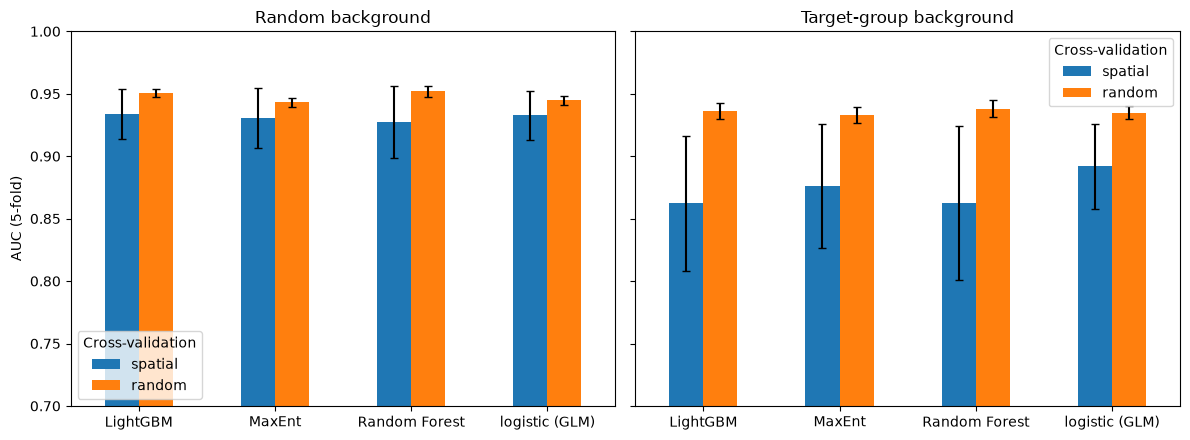

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, design in zip(axes, designs):
    table = results.loc[results["design"] == design].pivot_table(index="model", columns="cv", values="AUC")
    errors = results.loc[results["design"] == design].pivot_table(index="model", columns="cv", values="sd")
    table[["spatial", "random"]].plot.bar(ax=ax, yerr=errors[["spatial", "random"]], rot=0, capsize=3)
    ax.set(title=design.capitalize(), ylabel="AUC (5-fold)", xlabel="", ylim=(0.7, 1))
    ax.legend(title="Cross-validation")
plt.tight_layout()
plt.savefig(FIGURES / "03_model_comparison.png", dpi=150)

Three lessons:

1. **Random CV is optimistic, and the gap grows for flexible models.** Random Forest and LightGBM gain the most from random CV, because they are the best at memorising local patterns. Reporting random-CV AUC for spatial data is one of the most common mistakes in published SDMs.
2. **With spatial CV, the four models are practically tied.** The extra complexity of RF and LightGBM does not help predict new regions. By Occam's razor, we keep the **logistic regression**: equal performance, fully interpretable.
3. **The target-group AUC is lower, but that doesn't make it worse.** Its background is harder to tell apart (places where frog observers went), so the task is harder. AUCs from different backgrounds are not comparable.

## 5. Final model and suitability map

In [8]:
final_models = {}
for design, data in designs.items():
    model = MODELS["logistic (GLM)"]().fit(data[PREDICTORS], data["toad"])
    final_models[design] = model
    score = model.predict_proba(cells[PREDICTORS])[:, 1]
    threshold = np.quantile(score[cells["toad"] == 1], 0.10)
    cells[f"suitability ({design})"] = score
    cells[f"suitable ({design})"] = score >= threshold
    print(f"{design}: threshold {threshold:.3f}")

random background: threshold 0.141
target-group background: threshold 0.301


The model output is a **relative suitability score**, not a probability of presence (we never had true absences). To draw a "suitable / unsuitable" map we need a threshold. We use the **10th percentile of training presences**: the score above which 90% of the known toad cells fall, a common convention in SDMs.

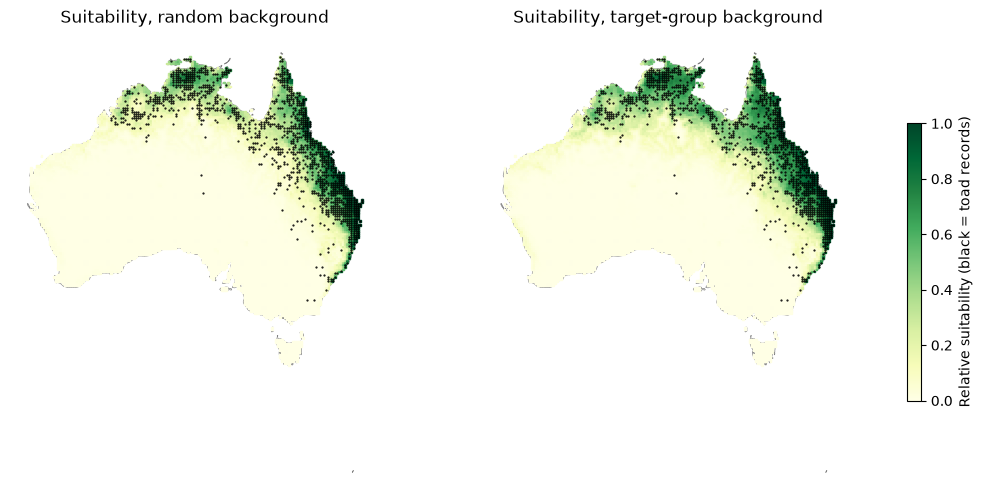

In [9]:
def plot_grid(ax, values, cmap, title, vmin=None, vmax=None):
    australia.plot(ax=ax, color="whitesmoke", edgecolor="grey", linewidth=0.5)
    image = ax.scatter(
        (cells["cx"] + 0.5) * CELL_SIZE_M, (cells["cy"] + 0.5) * CELL_SIZE_M,
        c=values, cmap=cmap, s=1.6, marker="s", vmin=vmin, vmax=vmax,
    )
    ax.set_axis_off()
    ax.set_title(title)
    return image


fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, design in zip(axes, designs):
    image = plot_grid(ax, cells[f"suitability ({design})"], "YlGn", f"Suitability, {design}", 0, 1)
    toads = cells.loc[cells["toad"] == 1]
    ax.scatter((toads["cx"] + 0.5) * CELL_SIZE_M, (toads["cy"] + 0.5) * CELL_SIZE_M, s=0.3, c="black")
plt.colorbar(image, ax=axes, shrink=0.6, label="Relative suitability (black = toad records)")
plt.savefig(FIGURES / "03_suitability_maps.png", dpi=150, bbox_inches="tight")

## 6. What drives suitability?

In [10]:
MAIN = "target-group background"
main_data = designs[MAIN]
importance = permutation_importance(
    final_models[MAIN], main_data[PREDICTORS], main_data["toad"], scoring="roc_auc", n_repeats=10, random_state=0
)
pd.Series(importance.importances_mean, index=PREDICTORS).sort_values(ascending=False).round(3).rename("AUC drop when shuffled")

annual_mean_temp          0.308
max_temp_warmest_month    0.171
annual_precip             0.150
precip_driest_quarter     0.061
min_temp_coldest_month    0.052
precip_seasonality        0.046
distance_to_river_km      0.027
elevation                 0.012
Name: AUC drop when shuffled, dtype: float64

**Permutation importance:** shuffle one variable and measure how much the AUC drops. The bigger the drop, the more the model relies on that variable.

Temperature dominates, followed by rainfall. That fits the biology of a tropical ectotherm that breeds in water. (Remember the caveat about correlated predictors: mean temperature probably takes credit shared with the minimum temperature.)

## 7. Back to the fronts

### Western front: is the Pilbara suitable?

In [11]:
regions = {
    "Kimberley (behind the front)": cells["lon"].between(124, 128) & cells["lat"].between(-18, -15),
    "Pilbara (ahead of the front)": cells["lon"].between(116, 121) & cells["lat"].between(-23, -19),
}
pd.DataFrame({
    region: {f"% suitable ({design})": 100 * cells.loc[mask, f"suitable ({design})"].mean() for design in designs}
    for region, mask in regions.items()
}).round(0)

,Kimberley (behind the front),Pilbara (ahead of the front)
% suitable (random background),75.0,0.0
% suitable (target-group background),76.0,0.0


**The model says the Pilbara is almost entirely unsuitable**, while three quarters of the Kimberley is suitable. That fits the slowing front seen in the notebook 02 backtest, and the idea (Tingley et al. 2013) that the arid Pilbara coast could act as a natural barrier.

**But beware the non-equilibrium trap.** The model learned from places toads have already reached. If the Pilbara climate is outside anything in the training presences, the model is **extrapolating**, and "unsuitable" may only mean "no toads there yet". Let's check how many Pilbara cells fall outside the range of the toad cells for each predictor:

In [12]:
presence_range = cells.loc[cells["toad"] == 1, PREDICTORS].agg(["min", "max"])
pilbara = cells.loc[regions["Pilbara (ahead of the front)"], PREDICTORS]
outside = ((pilbara < presence_range.loc["min"]) | (pilbara > presence_range.loc["max"])).mean() * 100
outside.round(0).rename("% of Pilbara cells outside the toads' current range")

annual_mean_temp          0.0
max_temp_warmest_month    9.0
min_temp_coldest_month    0.0
annual_precip             0.0
precip_seasonality        0.0
precip_driest_quarter     0.0
elevation                 0.0
distance_to_river_km      0.0
Name: % of Pilbara cells outside the toads' current range, dtype: float64

If most Pilbara cells are *inside* the range of each variable, the low suitability comes from the **combination** of conditions (e.g. hot *and* dry), not from pure extrapolation. That is more credible, but not proof: this check looks at one variable at a time. The real test is the native range (notebook 04): does the toad live in Pilbara-like climates in South America?

### Southern front: a climatic gradient?

In [13]:
east_coast = cells.loc[cells["lon"] > 149]
bands = pd.cut(east_coast["lat"], bins=[-36, -34, -33, -32, -31, -30, -29, -28])
pd.DataFrame({
    "% suitable": 100 * east_coast.groupby(bands, observed=True)[f"suitable ({MAIN})"].mean(),
    "% with toad records": 100 * east_coast.groupby(bands, observed=True)["toad"].mean(),
}).sort_index(ascending=False).round(0)

,% suitable,% with toad records
lat,,
"(-29, -28]",44.0,28.0
"(-30, -29]",24.0,19.0
"(-31, -30]",12.0,12.0
"(-32, -31]",15.0,6.0
"(-33, -32]",18.0,7.0
"(-34, -33]",17.0,24.0
"(-36, -34]",2.0,4.0


Suitability decreases southwards along the New South Wales coast, as expected for a cold limit. The band at 33–34°S has more toad records than its neighbours: that is **Sydney**, the population of transported toads identified in notebook 02.

## 8. How much of the suitable area is already invaded?

This connects the occupied-area question from notebook 02 with the suitability model: instead of "% of Australia", **% of the area where toads *can* live**.

In [14]:
summary = {}
for design in designs:
    suitable = cells[f"suitable ({design})"]
    summary[design] = {
        "suitable area (km²)": suitable.sum() * (CELL_SIZE_M / 1000) ** 2,
        "% of Australia suitable": 100 * suitable.mean(),
        "% of suitable cells with toad records": 100 * cells.loc[suitable, "toad"].mean(),
    }
pd.DataFrame(summary).T.round(1)

,suitable area (km²),% of Australia suitable,% of suitable cells with toad records
random background,1706875.0,22.2,43.2
target-group background,1641250.0,21.3,44.9


Toads have been recorded in **about 45% of the suitable 25 km cells**. Since recorded ≠ invaded (notebook 02), the true invaded share is higher; this is a lower bound.

## Takeaways and limitations

- **The four models perform about the same under spatial CV** (AUC ≈ 0.86–0.93 depending on the background). Logistic regression is enough, and interpretable.
- **Random CV inflates the AUC**, especially for flexible models. Spatial validation is not optional for spatial data.
- **Temperature and rainfall** drive suitability.
- **The Pilbara is predicted unsuitable**, which explains the slowing western front. **The southern NSW coast becomes less suitable with latitude**, which explains a slow, climate-limited southern front.
- About **45% of the suitable area** already has toad records (a lower bound).

**Limitations:**
1. **Non-equilibrium:** the toad is still spreading, so some "unsuitable" areas may just be unreached. → Notebook 04, native range.
2. **Climate normals (1970–2000):** no climate change, no year-to-year variation.
3. **Artificial water** (dams, cattle troughs) is not in HydroRIVERS, and it is exactly what might let toads cross the Pilbara.
4. **25 km resolution** hides microhabitats (a single creek in a dry cell).